# Bangla License Plate Deblurring - U-Net Baseline
Classic 4-level U-Net with skip connections and a global residual to the blurry input. Trained with L1 loss, same data and same image size as the other models so the comparison stays fair.

## Libraries

In [1]:
import os
import random
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

device = torch.device("cuda")
torch.backends.cudnn.benchmark = True
print("GPU:", torch.cuda.get_device_name(0))

GPU: NVIDIA GeForce RTX 3060


d:\_deblur gan\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Paths and settings

In [2]:
CLEAN_DIR = r"D:\_deblur gan\new dataset\fixed cropped"
GAUSSIAN_DIR = r"D:\_deblur gan\new dataset\light_gaussian_blurred"
MOTION_DIR = r"D:\_deblur gan\new dataset\light_motion_blurred"

IMG_H = 128
IMG_W = 256
BATCH_SIZE = 16
EPOCHS = 20
LR = 2e-4
VAL_SPLIT = 0.1
SEED = 42

BASE = 64

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

## Dataset (images are loaded into RAM once, so training is faster)

In [3]:
valid_ext = (".png", ".jpg", ".jpeg", ".bmp")

clean_names = sorted([f for f in os.listdir(CLEAN_DIR) if f.lower().endswith(valid_ext)])
random.shuffle(clean_names)

val_count = int(len(clean_names) * VAL_SPLIT)
val_names = clean_names[:val_count]
train_names = clean_names[val_count:]


def make_pairs(names):
    pairs = []
    for name in names:
        for blur_dir in (GAUSSIAN_DIR, MOTION_DIR):
            blur_path = os.path.join(blur_dir, name)
            if os.path.exists(blur_path):
                pairs.append((blur_path, os.path.join(CLEAN_DIR, name)))
    return pairs


class PlateDataset(Dataset):
    def __init__(self, pairs):
        self.blur = []
        self.clean = []
        for blur_path, clean_path in tqdm(pairs):
            self.blur.append(self.load(blur_path))
            self.clean.append(self.load(clean_path))

    def __len__(self):
        return len(self.blur)

    def load(self, path):
        img = Image.open(path).convert("RGB").resize((IMG_W, IMG_H), Image.BICUBIC)
        return torch.from_numpy(np.asarray(img).copy()).permute(2, 0, 1)

    def __getitem__(self, i):
        return self.blur[i].float() / 127.5 - 1, self.clean[i].float() / 127.5 - 1


train_pairs = make_pairs(train_names)
val_pairs = make_pairs(val_names)

train_loader = DataLoader(PlateDataset(train_pairs), batch_size=BATCH_SIZE, shuffle=True, num_workers=0, pin_memory=True, drop_last=True)
val_loader = DataLoader(PlateDataset(val_pairs), batch_size=BATCH_SIZE, shuffle=False, num_workers=0, pin_memory=True)

print("clean images:", len(clean_names))
print("train pairs:", len(train_pairs))
print("val pairs:", len(val_pairs))

100%|██████████| 398/398 [00:00<00:00, 462.00it/s]

clean images: 1991
train pairs: 3584
val pairs: 398


## U-Net building blocks

In [4]:
class DoubleConv(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.body = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.ReLU(True),
        )

    def forward(self, x):
        return self.body(x)


class Down(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.body = nn.Sequential(nn.MaxPool2d(2), DoubleConv(in_ch, out_ch))

    def forward(self, x):
        return self.body(x)


class Up(nn.Module):
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.up = nn.ConvTranspose2d(in_ch, in_ch // 2, 2, stride=2)
        self.conv = DoubleConv(in_ch, out_ch)

    def forward(self, x, skip):
        x = self.up(x)
        x = torch.cat([skip, x], dim=1)
        return self.conv(x)

## U-Net

In [5]:
class UNet(nn.Module):
    def __init__(self, base):
        super().__init__()
        self.inc = DoubleConv(3, base)
        self.down1 = Down(base, base * 2)
        self.down2 = Down(base * 2, base * 4)
        self.down3 = Down(base * 4, base * 8)
        self.down4 = Down(base * 8, base * 16)

        self.up1 = Up(base * 16, base * 8)
        self.up2 = Up(base * 8, base * 4)
        self.up3 = Up(base * 4, base * 2)
        self.up4 = Up(base * 2, base)

        self.out = nn.Conv2d(base, 3, 1)

    def forward(self, x):
        x1 = self.inc(x)
        x2 = self.down1(x1)
        x3 = self.down2(x2)
        x4 = self.down3(x3)
        x5 = self.down4(x4)

        y = self.up1(x5, x4)
        y = self.up2(y, x3)
        y = self.up3(y, x2)
        y = self.up4(y, x1)

        return self.out(y) + x

## Loss functions and metrics (PSNR, SSIM, MAE)

In [6]:
def ssim(fake, real, window=11, sigma=1.5):
    fake = (fake.clamp(-1, 1) + 1) / 2
    real = (real + 1) / 2
    coords = torch.arange(window, dtype=torch.float32, device=fake.device) - window // 2
    g = torch.exp(-(coords ** 2) / (2 * sigma ** 2))
    g = g / g.sum()
    kernel = (g[:, None] * g[None, :]).expand(3, 1, window, window).contiguous()
    mu_f = F.conv2d(fake, kernel, groups=3)
    mu_r = F.conv2d(real, kernel, groups=3)
    var_f = F.conv2d(fake * fake, kernel, groups=3) - mu_f ** 2
    var_r = F.conv2d(real * real, kernel, groups=3) - mu_r ** 2
    cov = F.conv2d(fake * real, kernel, groups=3) - mu_f * mu_r
    c1 = 0.01 ** 2
    c2 = 0.03 ** 2
    score = ((2 * mu_f * mu_r + c1) * (2 * cov + c2)) / ((mu_f ** 2 + mu_r ** 2 + c1) * (var_f + var_r + c2))
    return score.mean(dim=(1, 2, 3))


def mae(fake, real):
    return ((fake.clamp(-1, 1) - real).abs() * 127.5).mean(dim=(1, 2, 3))


def evaluate(net, loader):
    net.eval()
    p_all, s_all, m_all = [], [], []
    with torch.no_grad():
        for blur, clean in loader:
            blur = blur.to(device)
            clean = clean.to(device)
            fake = net(blur)
            if isinstance(fake, (list, tuple)):
                fake = fake[0]
            fake = fake.clamp(-1, 1)
            mse = (((fake + 1) / 2 - (clean + 1) / 2) ** 2).mean(dim=(1, 2, 3))
            p_all.append(10 * torch.log10(1 / (mse + 1e-8)))
            s_all.append(ssim(fake, clean))
            m_all.append(mae(fake, clean))
    return torch.cat(p_all), torch.cat(s_all), torch.cat(m_all)

## Model, optimizer, scheduler

In [7]:
model = UNet(BASE).to(device)

optimizer = torch.optim.Adam(model.parameters(), lr=LR, betas=(0.9, 0.999))
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS, eta_min=1e-6)

print("params:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

params: 31.037763 M


## Blurry input metrics (reference before training)

In [8]:
p, s, m = evaluate(nn.Identity(), val_loader)
print(f"Blurry input | PSNR {p.mean():.2f} | SSIM {s.mean():.4f} | MAE {m.mean():.2f}")

Blurry input | PSNR 26.27 | SSIM 0.8171 | MAE 9.01


## Checkpoint setup

In [9]:
CKPT_DIR = "checkpoints_unet"
os.makedirs(CKPT_DIR, exist_ok=True)
LAST_PATH = os.path.join(CKPT_DIR, "last.pth")
BEST_PATH = os.path.join(CKPT_DIR, "best.pth")

start_epoch = 0
best_psnr = 0.0
history = {"loss": [], "val_psnr": [], "val_ssim": [], "val_mae": []}

RESUME = False

if RESUME and os.path.exists(LAST_PATH):
    ckpt = torch.load(LAST_PATH, map_location=device)
    model.load_state_dict(ckpt["model"])
    optimizer.load_state_dict(ckpt["optimizer"])
    scheduler.load_state_dict(ckpt["scheduler"])
    history = ckpt["history"]
    best_psnr = ckpt["best_psnr"]
    start_epoch = ckpt["epoch"] + 1
    print("resumed from epoch", start_epoch)

## Training

In [10]:
for epoch in range(start_epoch, EPOCHS):
    model.train()
    loss_sum = 0

    for blur, clean in tqdm(train_loader, desc=f"Epoch {epoch + 1}/{EPOCHS}"):
        blur = blur.to(device, non_blocking=True)
        clean = clean.to(device, non_blocking=True)

        optimizer.zero_grad()
        fake = model(blur)
        loss = F.l1_loss(fake, clean)
        loss.backward()
        optimizer.step()

        loss_sum += loss.item()

    scheduler.step()

    p, s, m = evaluate(model, val_loader)
    val_psnr = p.mean().item()
    val_ssim = s.mean().item()
    val_mae = m.mean().item()

    history["loss"].append(loss_sum / len(train_loader))
    history["val_psnr"].append(val_psnr)
    history["val_ssim"].append(val_ssim)
    history["val_mae"].append(val_mae)

    print(f"epoch {epoch + 1} | loss {history['loss'][-1]:.4f} | val PSNR {val_psnr:.2f} | SSIM {val_ssim:.4f} | MAE {val_mae:.2f}")

    if history["val_psnr"][-1] > best_psnr:
        best_psnr = history["val_psnr"][-1]
        torch.save(model.state_dict(), BEST_PATH)

    torch.save({
        "model": model.state_dict(),
        "optimizer": optimizer.state_dict(),
        "scheduler": scheduler.state_dict(),
        "history": history,
        "best_psnr": best_psnr,
        "epoch": epoch,
    }, LAST_PATH)

Epoch 1/20: 100%|██████████| 224/224 [01:14<00:00,  3.02it/s]


epoch 1 | loss 0.0765 | val PSNR 27.17 | SSIM 0.8316 | MAE 8.28


Epoch 2/20: 100%|██████████| 224/224 [01:07<00:00,  3.32it/s]


epoch 2 | loss 0.0634 | val PSNR 27.68 | SSIM 0.8492 | MAE 7.64


Epoch 3/20: 100%|██████████| 224/224 [01:09<00:00,  3.25it/s]


...

epoch 18 | loss 0.0354 | val PSNR 32.25 | SSIM 0.9299 | MAE 4.46


Epoch 19/20: 100%|██████████| 224/224 [01:10<00:00,  3.17it/s]


epoch 19 | loss 0.0352 | val PSNR 32.29 | SSIM 0.9303 | MAE 4.44


Epoch 20/20: 100%|██████████| 224/224 [01:11<00:00,  3.15it/s]


epoch 20 | loss 0.0352 | val PSNR 32.32 | SSIM 0.9310 | MAE 4.42


## Training curves

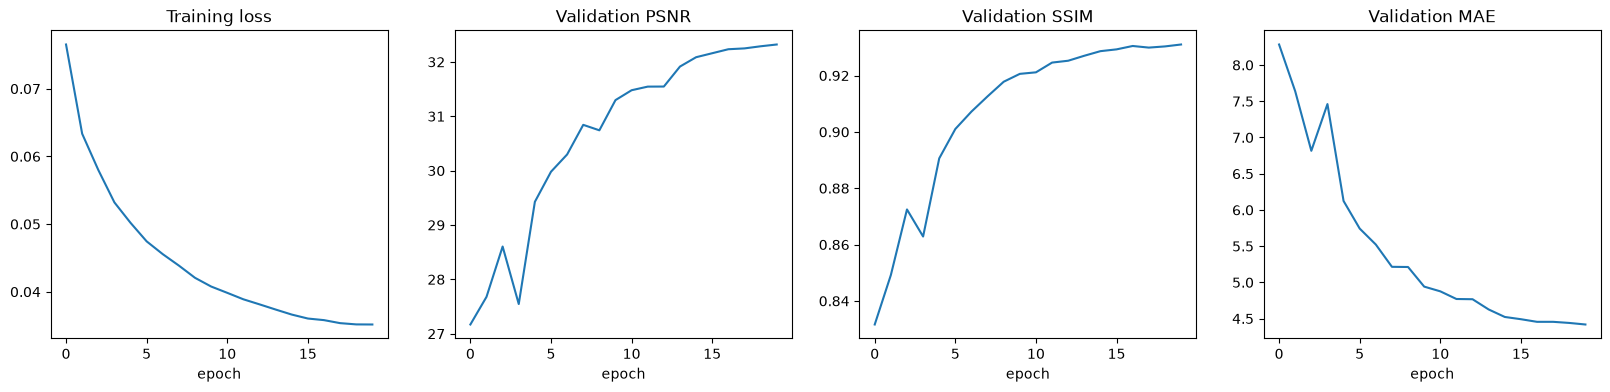

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(20, 4))
axes[0].plot(history["loss"])
axes[0].set_title("Training loss")
axes[1].plot(history["val_psnr"])
axes[1].set_title("Validation PSNR")
axes[2].plot(history["val_ssim"])
axes[2].set_title("Validation SSIM")
axes[3].plot(history["val_mae"])
axes[3].set_title("Validation MAE")
for ax in axes:
    ax.set_xlabel("epoch")
plt.show()

## Visual results

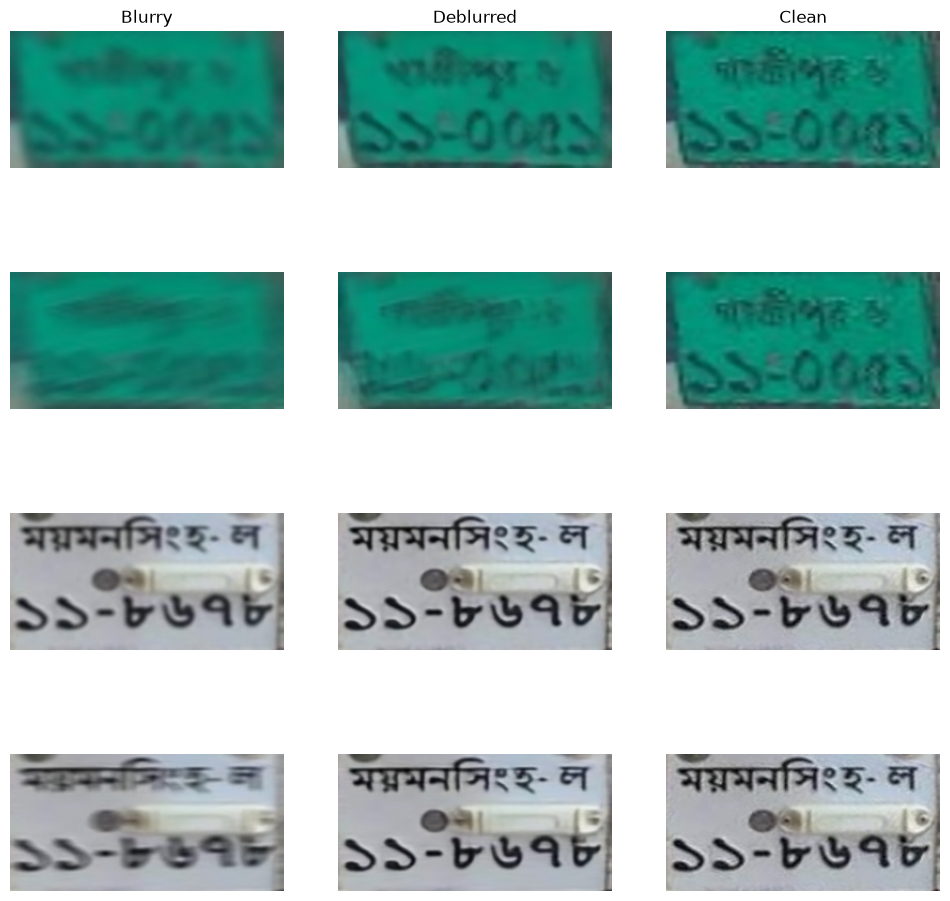

In [12]:
model.eval()
blur, clean = next(iter(val_loader))
with torch.no_grad():
    fake = model(blur.to(device)).clamp(-1, 1).cpu()


def show(t):
    return ((t.permute(1, 2, 0) + 1) / 2).clamp(0, 1).numpy()


n = min(4, blur.size(0))
fig, axes = plt.subplots(n, 3, figsize=(12, 3 * n), squeeze=False)
for i in range(n):
    axes[i][0].imshow(show(blur[i]))
    axes[i][1].imshow(show(fake[i]))
    axes[i][2].imshow(show(clean[i]))
    for j in range(3):
        axes[i][j].axis("off")
axes[0][0].set_title("Blurry")
axes[0][1].set_title("Deblurred")
axes[0][2].set_title("Clean")
plt.show()

Final evaluation with the best weights

In [13]:
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
p, s, m = evaluate(model, val_loader)
p, s, m = p.cpu().numpy(), s.cpu().numpy(), m.cpu().numpy()

is_motion = np.array([os.path.dirname(b) == MOTION_DIR for b, _ in val_pairs])
groups = {"all": np.ones(len(p), dtype=bool), "gaussian": ~is_motion, "motion": is_motion}

for name, mask in groups.items():
    print(f"{name:9s} | PSNR {p[mask].mean():.2f} | SSIM {s[mask].mean():.4f} | MAE {m[mask].mean():.2f}")

C:\Users\Sagar\AppData\Local\Temp\ipykernel_7788\3350501376.py:1: FutureWarning: You are using `torch.load` with `weights_only=False` (the current default value), which uses the default pickle module implicitly. It is possible to construct malicious pickle data which will execute arbitrary code during unpickling (See https://github.com/pytorch/pytorch/blob/main/SECURITY.md#untrusted-models for more details). In a future release, the default value for `weights_only` will be flipped to `True`. This limits the functions that could be executed during unpickling. Arbitrary objects will no longer be allowed to be loaded via this mode unless they are explicitly allowlisted by the user via `torch.serialization.add_safe_globals`. We recommend you start setting `weights_only=True` for any use case where you don't have full control of the loaded file. Please open an issue on GitHub for any issues related to this experimental feature.
  model.load_state_dict(torch.load(BEST_PATH, map_location=devi

all       | PSNR 32.32 | SSIM 0.9310 | MAE 4.42
gaussian  | PSNR 34.40 | SSIM 0.9512 | MAE 3.45
motion    | PSNR 30.24 | SSIM 0.9108 | MAE 5.39
